# Benchmark NumPy vs PyTorch: EchoStateNetwork & MemristiveReservoir
Este notebook compara el rendimiento de dos implementaciones (NumPy y PyTorch) de la dependencia reservoir.
- Se valida equivalencia entre salidas.
- Se mide tiempo de ejecución.
- Incluye gráficos finales.

In [13]:
import numpy as np
import torch
import time
import matplotlib.pyplot as plt

import reservoir_numpy as np_res
import reservoir_torch as torch_res

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Dispositivo detectado: {device.upper()}")

Dispositivo detectado: CUDA


In [17]:
sizes = [100, 300, 500, 700, 1000]
results = {'esn': {'numpy': [], 'torch': []}, 'mem': {'numpy': [], 'torch': []}}

In [20]:
import importlib.util

def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

np_res = load_module("reservoir_numpy", "./reservoir_numpy.py")
print("¿simulate existe?:", hasattr(np_res.MemristiveReservoir, "simulate"))
print("¿updateG existe?:", hasattr(np_res.MemristiveReservoir, "updateG"))


¿simulate existe?: True
¿updateG existe?: True


In [ ]:
for N in sizes:
    print(f"\n{'='*30}\nTamaño: {N}\n{'='*30}")
    T = 500
    n_inputs = 10

    W = np.random.rand(N, N) * 0.1
    w_in = np.random.rand(n_inputs, N)
    ext_input = np.random.rand(T, n_inputs)

    # ---------- ESN ----------
    esn_np = np_res.EchoStateNetwork(W)
    start = time.perf_counter()
    state_np = esn_np.simulate(ext_input, w_in)
    time_np = time.perf_counter() - start
    results['esn']['numpy'].append(time_np)

    W_torch = torch.tensor(W, dtype=torch.float32).to(device)
    ext_input_torch = torch.tensor(ext_input, dtype=torch.float32).to(device)
    w_in_torch = torch.tensor(w_in, dtype=torch.float32).to(device)

    esn_torch = torch_res.EchoStateNetwork(W_torch, device=device)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        state_torch = esn_torch.simulate(ext_input_torch, w_in_torch)
    torch.cuda.synchronize()
    time_torch = time.perf_counter() - start
    results['esn']['torch'].append(time_torch)

    equivalent_esn = np.allclose(state_np, state_torch.cpu().numpy(), atol=1e-4)
    print(f"ESN NumPy: {time_np:.4f}s | Torch: {time_torch:.4f}s | Equivalente: {equivalent_esn}")

    # ---------- MEM ----------
    W_bin = (np.random.rand(N, N) > 0.98).astype(int)
    int_nodes = np.arange(0, int(0.6 * N))
    ext_nodes = np.arange(int(0.6 * N), int(0.9 * N))
    gr_nodes = np.arange(int(0.9 * N), N)
    Vext = np.random.rand(T, len(ext_nodes))

    mem_np = np_res.MemristiveReservoir(W_bin, int_nodes, ext_nodes, gr_nodes)
    mem_np._G = np.eye(N)
    start = time.perf_counter()
    mem_state_np = mem_np.simulate(Vext)
    time_np_mem = time.perf_counter() - start
    results['mem']['numpy'].append(time_np_mem)

    W_bin_torch = torch.tensor(W_bin, dtype=torch.float32).to(device)
    Vext_torch = torch.tensor(Vext, dtype=torch.float32).to(device)

    mem_torch = torch_res.MemristiveReservoir(W_bin_torch, int_nodes, ext_nodes, gr_nodes, device=device)
    mem_torch._G = torch.eye(N).to(device)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        mem_state_torch = mem_torch.simulate(Vext_torch)
    torch.cuda.synchronize()
    time_torch_mem = time.perf_counter() - start
    results['mem']['torch'].append(time_torch_mem)

    equivalent_mem = np.allclose(mem_state_np, mem_state_torch.cpu().numpy(), atol=1e-4)
    print(f"MEM NumPy: {time_np_mem:.4f}s | Torch: {time_torch_mem:.4f}s | Equivalente: {equivalent_mem}")


Tamaño: 100
ESN NumPy: 0.0021s | Torch: 0.4083s | Equivalente: True

 GENERATING RESERVOIR STATES ...

 SIMULATING STATES IN FORWARD MODE ...
	 ----- timestep = 2
	 ----- timestep = 4
	 ----- timestep = 6
	 ----- timestep = 8
	 ----- timestep = 10
	 ----- timestep = 12
	 ----- timestep = 14
	 ----- timestep = 16
	 ----- timestep = 18
	 ----- timestep = 20
	 ----- timestep = 22
	 ----- timestep = 24
	 ----- timestep = 26
	 ----- timestep = 28
	 ----- timestep = 30
	 ----- timestep = 32
	 ----- timestep = 34
	 ----- timestep = 36
	 ----- timestep = 38
	 ----- timestep = 40
	 ----- timestep = 42
	 ----- timestep = 44
	 ----- timestep = 46
	 ----- timestep = 48
	 ----- timestep = 50
	 ----- timestep = 52
	 ----- timestep = 54
	 ----- timestep = 56
	 ----- timestep = 58
	 ----- timestep = 60
	 ----- timestep = 62
	 ----- timestep = 64
	 ----- timestep = 66
	 ----- timestep = 68
	 ----- timestep = 70
	 ----- timestep = 72
	 ----- timestep = 74
	 ----- timestep = 76
	 ----- timestep = 78
	 -

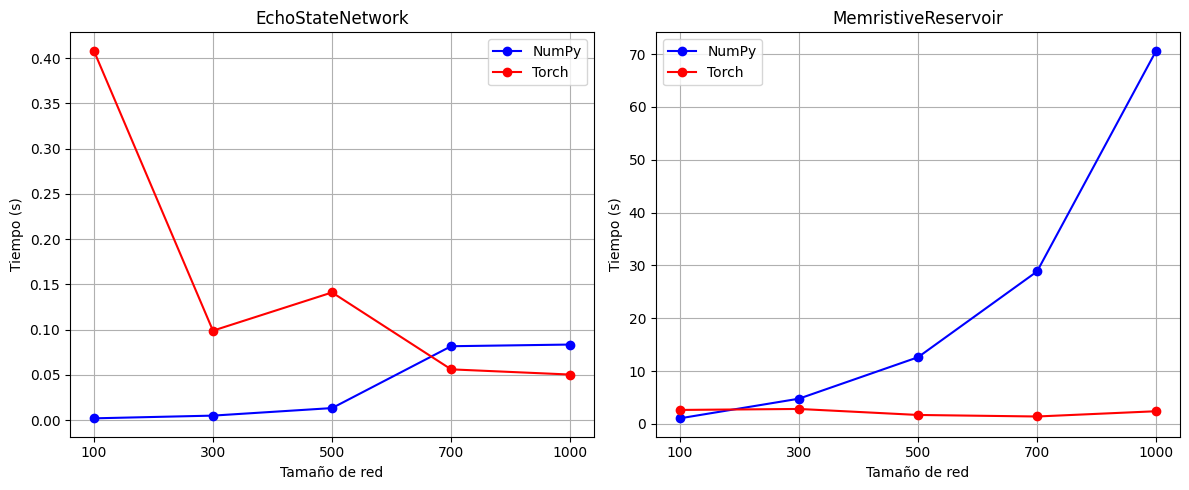

In [22]:
# Gráficas comparativas
x = range(len(sizes))
labels = [str(s) for s in sizes]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x, results['esn']['numpy'], 'bo-', label='NumPy')
plt.plot(x, results['esn']['torch'], 'ro-', label='Torch')
plt.xticks(x, labels)
plt.title('EchoStateNetwork')
plt.xlabel('Tamaño de red')
plt.ylabel('Tiempo (s)')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, results['mem']['numpy'], 'bo-', label='NumPy')
plt.plot(x, results['mem']['torch'], 'ro-', label='Torch')
plt.xticks(x, labels)
plt.title('MemristiveReservoir')
plt.xlabel('Tamaño de red')
plt.ylabel('Tiempo (s)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()